In [1]:
# Notebook nằm trong notebooks/; chuyển cwd về thư mục gốc repo để src/ và kaggle_3m/ hoạt động.
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

import matplotlib.pyplot as plt
from src.dataset import load_dataset
import numpy as np

### Show dataset

(256, 256, 3) uint8
(256, 256) 1


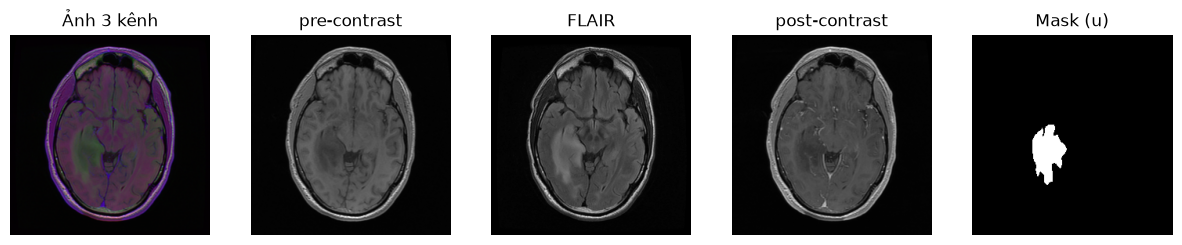

In [2]:
# 1 ca DÙNG XUYÊN SUỐT notebook: minh hoạ kênh/mask, histogram trước-sau lọc, và là ca
# "ranh giới" (không lọc -> phân đoạn sai, có lọc median -> đúng) ở cuối phần tiền xử lý
sample = next(s for s in load_dataset(tumour_only=True)
              if s.image_path.stem == "TCGA_HT_7879_19981009_14")
print(sample.image.shape, sample.image.dtype)   # (256, 256, 3) uint8
print(sample.mask.shape, sample.mask.max())      # (256, 256) 1

fig, ax = plt.subplots(1, 5, figsize=(15, 3))
ax[0].imshow(sample.image)                       # gộp 3 kênh (giả màu)
ax[0].set_title("Ảnh 3 kênh")
ax[1].imshow(sample.image[:, :, 0], cmap="gray"); ax[1].set_title("pre-contrast")
ax[2].imshow(sample.image[:, :, 1], cmap="gray"); ax[2].set_title("FLAIR")
ax[3].imshow(sample.image[:, :, 2], cmap="gray"); ax[3].set_title("post-contrast")
ax[4].imshow(sample.mask, cmap="gray");           ax[4].set_title("Mask (u)")
for a in ax: a.axis("off")
plt.show()

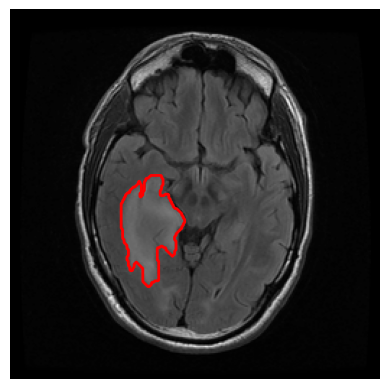

In [3]:
flair = sample.image[:, :, 1]

plt.imshow(flair, cmap="gray")
plt.contour(sample.mask, levels=[0.5], colors="red", linewidths=2)  # viền đỏ theo mask GT
plt.axis("off"); plt.show()

### Phương pháp

#### Tiền xử lý

In [4]:
# Đo độ tương phản để chọn kênh FLAIR

names = ["pre-contrast", "FLAIR", "post-contrast"]
diffs = {n: [] for n in names} # Một dict chứa 3 danh sách để đo giá trị tương phản trên từng ảnh, sau đó lấy trung bình
for s in load_dataset(limit=30, tumour_only=True): # lấy 30 ảnh có u
    img, m = s.image.astype(float), s.mask.astype(bool) # chuyển sang floating point để tính trung bình cho chính xác, còn mask ép thành true/false
    for i, n in enumerate(names): # tính tương phản cho từng kênh
        ch = img[..., i]
        # cường độ sáng trung bình u - mô não (bỏ nền)
        diffs[n].append(ch[m].mean() - ch[(~m) & (ch > 10)].mean())
print("Độ tương phản trung bình (u - nền) theo kênh (30 ca):")
for n in names:
    print(f"  {n:15s}: {np.mean(diffs[n]):+6.1f}")


Độ tương phản trung bình (u - nền) theo kênh (30 ca):
  pre-contrast   :   -9.3
  FLAIR          :  +47.4
  post-contrast  :   -2.3


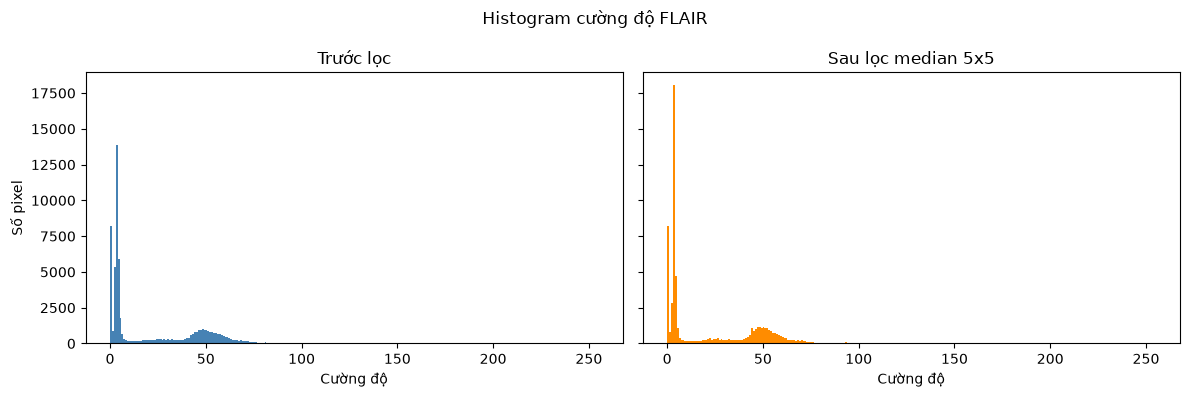

In [5]:
# Histogram cường độ FLAIR: trước và sau lọc median 5x5 
from src.preprocessing import to_intensity, median_filter

flair = to_intensity(sample.image, "flair") # Trước lọc
flair_med = median_filter(flair, kernel_size=5) # Sau lọc

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

ax[0].hist(flair.ravel(), bins=256, range=(0, 255), color="steelblue")
ax[0].set_title("Trước lọc")
ax[0].set_xlabel("Cường độ"); ax[0].set_ylabel("Số pixel")
ax[1].hist(flair_med.ravel(), bins=256, range=(0, 255), color="darkorange")
ax[1].set_title("Sau lọc median 5x5")
ax[1].set_xlabel("Cường độ")
fig.suptitle("Histogram cường độ FLAIR")
plt.tight_layout(); plt.show()

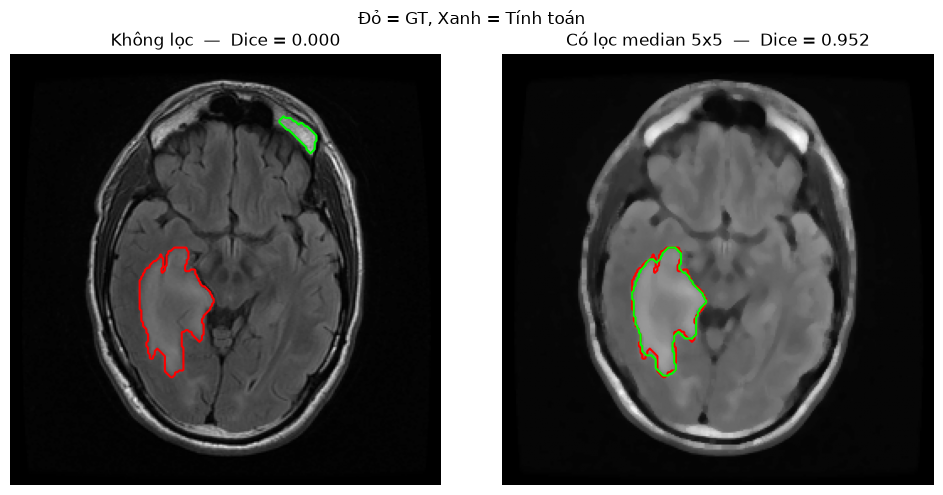

In [6]:
import cv2
from skimage.filters import threshold_multiotsu
from src.metrics import dice
from src.methods import MORPH_KERNEL, MIN_FOREGROUND, _keep_largest_component

def _seg_from_intensity(f, morph_iter=2):
    """otsu_postproc nhưng nhận thẳng ảnh cường độ -> để bật/tắt bước lọc median."""
    z = np.zeros(f.shape, np.uint8)
    if f.max() < MIN_FOREGROUND:
        return z
    try:
        th = threshold_multiotsu(f, classes=3)
    except ValueError:
        return z
    m = (f > th[-1]).astype(np.uint8)
    if m.max() == 0:
        return m
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, MORPH_KERNEL, iterations=morph_iter)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, MORPH_KERNEL, iterations=morph_iter)
    return _keep_largest_component(m)

pred_no, pred_med = _seg_from_intensity(flair), _seg_from_intensity(flair_med)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for a, (f, p, t) in zip(ax, [(flair, pred_no, "Không lọc"), (flair_med, pred_med, "Có lọc median 5x5")]):
    a.imshow(f, cmap="gray")
    a.contour(sample.mask, levels=[0.5], colors="red", linewidths=1.5)   # GT
    if p.sum() > 0:
        a.contour(p, levels=[0.5], colors="lime", linewidths=1.5)          # phân đoạn
    a.set_title(f"{t}  —  Dice = {dice(p, sample.mask):.3f}")
    a.axis("off")
plt.suptitle("Đỏ = GT, Xanh = Tính toán")
plt.tight_layout(); plt.show()

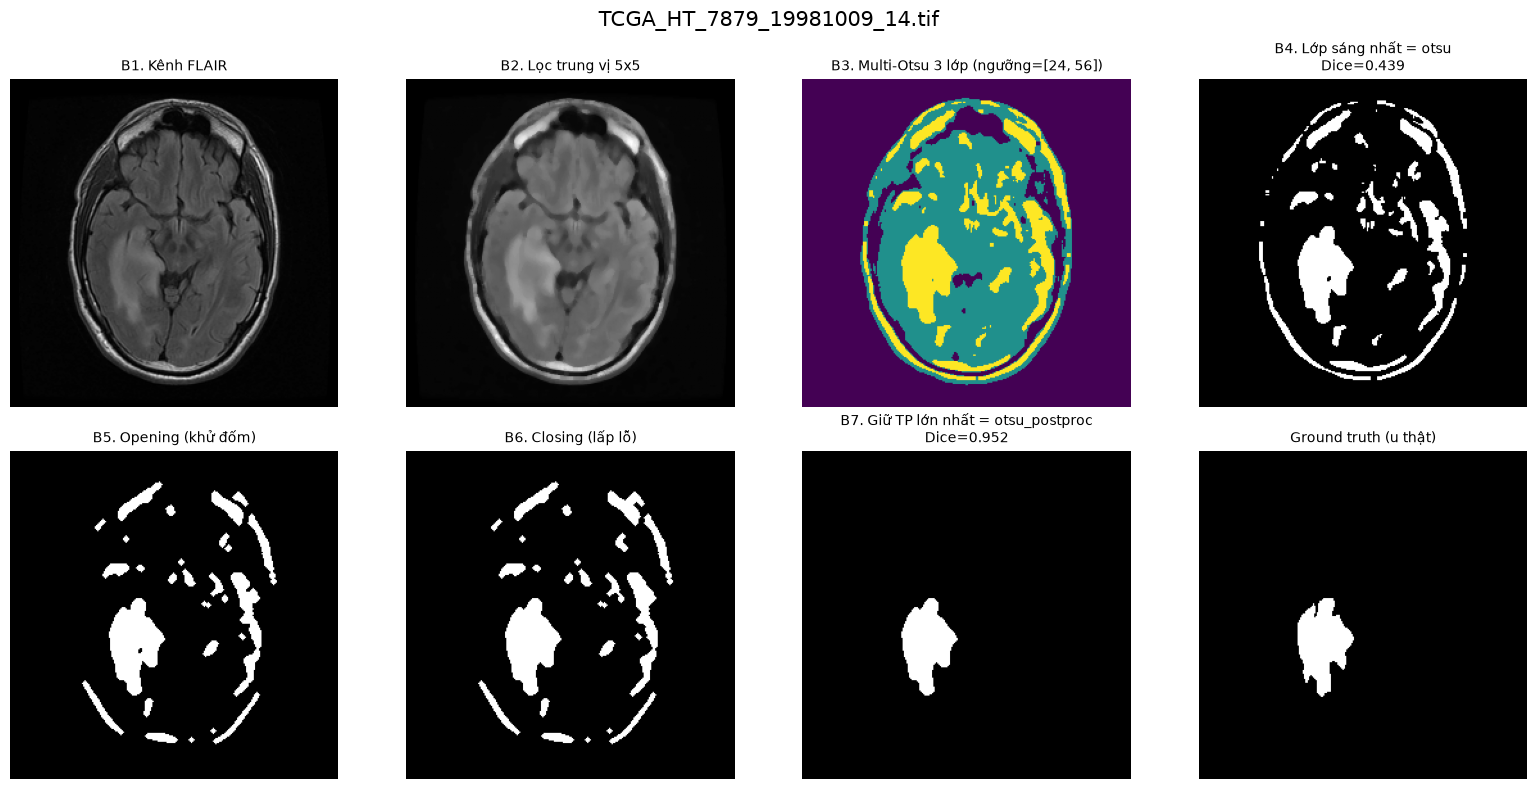

  B4 otsu       :   6567 px
  B5 opening    :   5217 px
  B6 closing    :   5298 px
  B7 otsu_postproc:   1957 px
  GT            :   2013 px


In [7]:
step_s = sample
gt = step_s.mask

flair_s = to_intensity(step_s.image, "flair")          # B1: tách kênh FLAIR
med_s   = median_filter(flair_s, 5)                    # B2: lọc trung vị 5x5
th_s    = threshold_multiotsu(med_s, classes=3)        # B3: 2 ngưỡng -> 3 lớp
regions = np.digitize(med_s, bins=th_s)                # minh hoạ 3 lớp (nền/não/u)
otsu_m  = (med_s > th_s[-1]).astype(np.uint8)          # B4: lớp sáng nhất = otsu
opened  = cv2.morphologyEx(otsu_m, cv2.MORPH_OPEN,  MORPH_KERNEL, iterations=2)   # B5
closed  = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, MORPH_KERNEL, iterations=2)   # B6
morph_m = _keep_largest_component(closed)              # B7: giữ TP lớn nhất = otsu_postproc

panels = [
    (flair_s, "B1. Kênh FLAIR", "gray"),
    (med_s,   "B2. Lọc trung vị 5x5", "gray"),
    (regions, f"B3. Multi-Otsu 3 lớp (ngưỡng={th_s.tolist()})", "viridis"),
    (otsu_m,  f"B4. Lớp sáng nhất = otsu\nDice={dice(otsu_m, gt):.3f}", "gray"),
    (opened,  "B5. Opening (khử đốm)", "gray"),
    (closed,  "B6. Closing (lấp lỗ)", "gray"),
    (morph_m, f"B7. Giữ TP lớn nhất = otsu_postproc\nDice={dice(morph_m, gt):.3f}", "gray"),
    (gt,      "Ground truth (u thật)", "gray"),
]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (data, title, cmap) in zip(axes.ravel(), panels):
    ax.imshow(data, cmap=cmap); ax.set_title(title, fontsize=10); ax.axis("off")
fig.suptitle(f"{step_s.image_path.name}", fontsize=15)
plt.tight_layout(); plt.show()

for label_, m in [("B4 otsu", otsu_m), ("B5 opening", opened),
                  ("B6 closing", closed), ("B7 otsu_postproc", morph_m), ("GT", gt)]:
    print(f"  {label_:14s}: {int(np.asarray(m).sum()):6d} px")